# Lab 1.13 · LLM prefill and decode bottlenecks

**15–20 minutes · CPU**

Read the [lab guide](README.md), then run the setup. Replace each `return None` with your implementation and rerun its check.

## Concepts and worked example

Why can the limiting resource change between the prompt and the generated tokens?

In Kiely's comparison, prefill processes many prompt positions together and can reuse model weights across those positions. One decode step processes one new position per active sequence and typically has less weight reuse. Batching decode requests increases reuse, while longer contexts can increase traffic from reading cached keys and values. These are tendencies. Shapes, hardware, and implementation can change the result.

We use two separate estimates. First, a FP16 projection has ideal intensity `2MKN / [2(MK + KN + MN)]` for M rows. For K=N=1024, M=1 gives about 1 FLOP/byte and M=256 about 171 FLOP/byte. Second, a cached attention step reads K and V for earlier tokens. With 4 key/value positions, 2 KV heads, a head width of 8, and 2 bytes per value, that is `2 × 4 × 2 × 8 × 2 = 256` bytes per layer per sequence. The factor of two counts the K and V arrays. A single cached query uses one row of scores per query head. A full multi-query attention calculation has more than one row.

Here, M counts rows processed together by a projection. Those rows can come from one long prompt or from several sequences during decode. The projection estimate assumes one weight read, while the KV estimate counts separate reads for each sequence. Compare them as two sources of work and traffic before reasoning about the whole model.

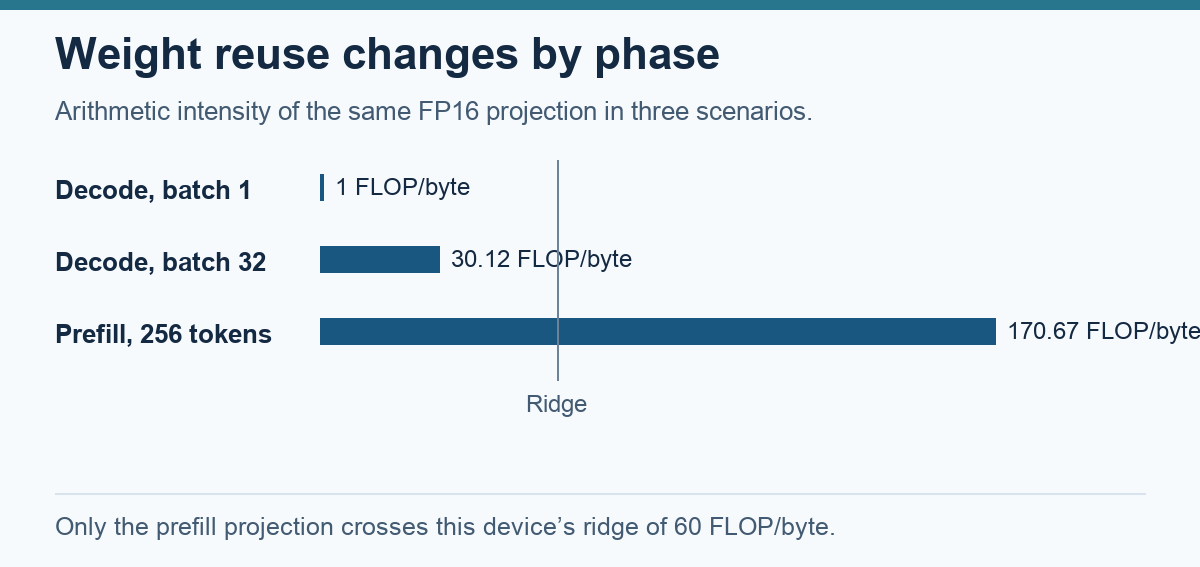

## Exercise map

| Exercise | What you will do | What to inspect |
| --- | --- | --- |
| 1. Compare projection reuse | Vary rows for unbatched decode, batched decode, and prefill. | Which scenarios reach the ridge? |
| 2. Estimate KV reads | Vary context and batch size with a fixed KV head layout. | How much cache traffic grows independently of the shared weights? |

Reading companion for Section 2.4.2, pp. 63–66 of *Inference Engineering* by Philip Kiely (Baseten Books).

In [ ]:
from math import isclose

width = 1024
ridge = 60  # FLOP/byte for the illustrative device in Lab 1.12
scenarios = {"decode, batch 1": 1, "decode, batch 32": 32, "prefill, 256 tokens": 256}

## Exercise 1. Model weight reuse

Return FLOP/byte for a square FP16 projection with the given number of token rows. Count writing the output. Each scenario shares a single copy of the projection weights.

**Implementation hint** · Use M = rows and K = N = width. Count the input and output separately, even though they have the same shape.

**Interpret the result** · Batching moves the projection closer to the ridge. The batch of 32 in this example still falls below it.

In [ ]:
def projection_intensity(rows, width):
    return None

In [ ]:
single = projection_intensity(1, width)
if single is not None:
    intensities = [projection_intensity(rows, width) for rows in scenarios.values()]
    assert isclose(projection_intensity(2, 2), 2 / 3)
    assert intensities[0] < intensities[1] < ridge < intensities[2]
    for name, ai in zip(scenarios, intensities):
        print(name, round(ai, 2), "FLOP/byte", "bandwidth" if ai < ridge else "compute")
    print("PASS — the modeled projection crosses the ridge as reuse rises")
else:
    print("Complete the implementation and any earlier exercises, then rerun this check.")

### Read the result

The projection alone crosses the ridge in the higher-reuse case. Keep its conclusion scoped to that operation.

## Exercise 2. Count KV cache reads

Return total bytes for reading K and V once for each cached position and each sequence. Multiply by the number of layers. Use KV heads, which can be fewer than query heads. The model ignores new cache writes, rereads, and temporary tensors.

**Implementation hint** · Start from one position in one layer of one sequence. Count both K and V, then multiply by context, layers, and batch.

**Interpret the result** · The result is the modeled traffic for one decode step across this batch. The same bytes may also be read on later steps.

In [ ]:
def kv_read_bytes(context, batch, layers, kv_heads, head_width, bytes_per_value=2):
    return None

In [ ]:
tiny = kv_read_bytes(4, 1, 1, 2, 8)
if tiny is not None:
    assert tiny == 256
    base = kv_read_bytes(512, 1, 16, 4, 64)
    assert kv_read_bytes(1024, 1, 16, 4, 64) == 2 * base
    assert kv_read_bytes(512, 8, 16, 4, 64) == 8 * base
    for context, batch in ((512, 1), (1024, 1), (512, 8)):
        print(context, "cached positions,", batch, "sequences:",
              kv_read_bytes(context, batch, 16, 4, 64) / 2**20, "MiB")
    print("PASS — KV reads grow with context and batch")
else:
    print("Complete the implementation and any earlier exercises, then rerun this check.")

### Read the result

The cache estimate grows with sequences and context independently of the projection estimate. Check that your count includes both K and V.

## Compare your results

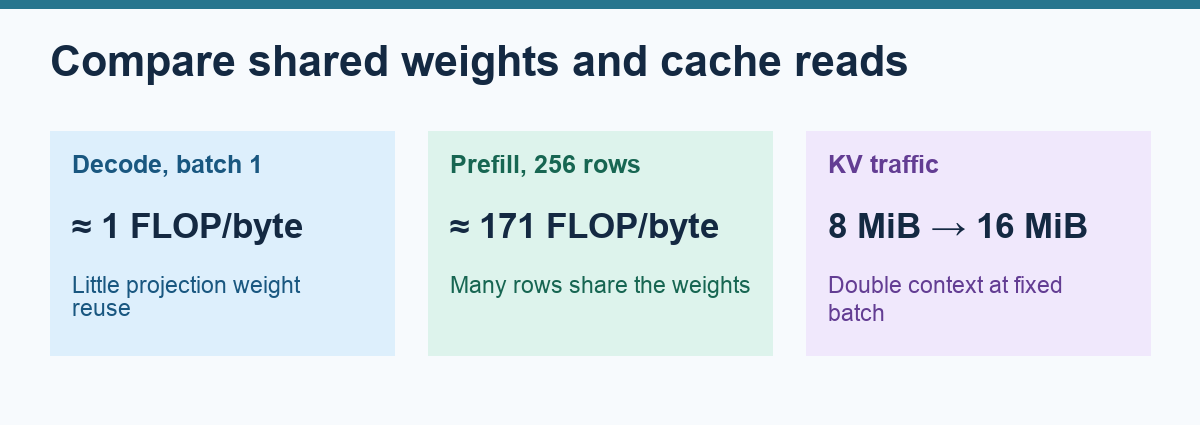

## Wrap-up

Why can batching improve weight reuse while increasing total KV reads? Which measurements would you need before claiming that the whole decoder is bandwidth-limited?

## Optional system exercise · Separating shared and per-sequence traffic

The worked attention example on pp. 64–66 uses N query rows and an N × N score matrix. Those shapes describe a full-sequence calculation. For the one-token cached decode case in this lab, use one query row per query head and keys and values for all visible positions. Keep the book's method of counting work and traffic, and substitute the shapes of the operation you are analyzing.

Estimate the KV reads for a batch with context lengths 512 and 1024 by summing the two single-sequence estimates. Compare with a model that reads both sequences up to the longest padded length. State which assumptions a profiler or runtime trace could validate.